## Packages

In [ ]:
# Package imports
import os
import numpy as np
import pandas as pd
import copy
import matplotlib.pyplot as plt
import sklearn
import sklearn.datasets
import sklearn.linear_model
from time import perf_counter      

from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import MinMaxScaler

## Loading and Preparing Data

The data is read in and merged into one big dataset.

In [22]:
# Loading the data
weather_2021 = pd.read_csv("Data/ninja_weather_2021.csv", comment="#")
weather_2022 = pd.read_csv("Data/ninja_weather_2022.csv", comment="#")
weather_2023 = pd.read_csv("Data/ninja_weather_2023.csv", comment="#")
weather_2024 = pd.read_csv("Data/ninja_weather_2024.csv", comment="#")
weather_2025 = pd.read_csv("Data/ninja_weather_2025.csv", comment="#")

pv_2021 = pd.read_csv("Data/ninja_pv_2021.csv", comment="#")
pv_2022 = pd.read_csv("Data/ninja_pv_2022.csv", comment="#")
pv_2023 = pd.read_csv("Data/ninja_pv_2023.csv", comment="#")
pv_2024 = pd.read_csv("Data/ninja_pv_2024.csv", comment="#")
pv_2025 = pd.read_csv("Data/ninja_pv_2025.csv", comment="#")

# merge the three years
weather = pd.concat([weather_2021, weather_2022, weather_2023, weather_2024, weather_2025], ignore_index=True)
pv = pd.concat([pv_2021, pv_2022, pv_2023, pv_2024, pv_2025], ignore_index=True)

# merge weather and pv data
data = pd.merge(weather, pv, on="time")

data["time"] = pd.to_datetime(data["time"])    # timestamps as datetime
data = data.set_index("time")                  # datetime index

time = data.index                              # keep the timestamps
input_data = data.values                       # .values converts a pandas dataframe to a numpy array

In [ ]:
#Categorizing the data into inputs (x) and outputs (y) as well as training set and testing set
split = int(0.8 * input_data.shape[0])   # 80/20 split

train_set_x_orig = input_data[:split, 0:8]
test_set_x_orig = input_data[split:, 0:8]
train_set_y_orig = input_data[:split, -1:]
test_set_y_orig = input_data[split:, -1:]

## Model (based on tutorial)


**Mathematical expression of the algorithm**:

$$
z^{(i)} = w^T x^{(i)} + b \tag{1}
$$

$$
\hat{y}^{(i)} = a^{(i)} = \sigma(z^{(i)}) \tag{2}
$$

$$
\mathcal{L}(a^{(i)}, y^{(i)}) = - y^{(i)} \log(a^{(i)}) - (1-y^{(i)}) \log(1-a^{(i)}) \tag{3}
$$


$$
J = \frac{1}{m} \sum_{i=1}^m \mathcal{L}(a^{(i)}, y^{(i)}) \tag{4}
$$


### Forward and Backward propagation

$$ \frac{\partial J}{\partial w} = \frac{1}{m}X(A-Y)^T\tag{5}$$
$$ \frac{\partial J}{\partial b} = \frac{1}{m} \sum_{i=1}^m (a^{(i)}-y^{(i)})\tag{6}$$

### Helper Functions

In [24]:
# Sigmoid function
def sigmoid(z):
    
    s = 1 / (1 + np.exp(-z))
    
    return s

#initilisation
def initialize_with_zeros(dim):

    w = np.zeros((dim, 1))
    b = float(0)

    return w, b

In [ ]:
def propagate(w, b, X, Y):

    m = X.shape[1]                  
    A = sigmoid(np.dot(w.T, X) + b) 

    cost = -1/m * np.sum(Y * np.log(A) + (1 - Y) * np.log(1 - A))                       

    dw = 1/m * np.dot(X, (A - Y).T)

    db = 1/m * np.sum(A - Y)

    grads = {"dw": dw,
              "db": db}
   
    
    return grads, cost

### Optimization

In [26]:
def optimize(w, b, X, Y, num_iterations=2000, learning_rate=0.009, print_cost=False):

    w = copy.deepcopy(w)
    b = copy.deepcopy(b)

    costs = []

    for i in range(num_iterations):
        grads, cost = propagate(w, b, X, Y)

        dw = grads["dw"]
        db = grads["db"]

        w = w - learning_rate * dw
        b = b - learning_rate * db

        params = {"w": w,
                  "b": b}

        grads = {"dw": dw,
                  "db": db}

        if i % 100 == 0:
            costs.append(cost)

            # Print the cost every 100 training iterations
            if print_cost:
                print ("Cost after iteration %i: %f" %(i, cost))
    
    return params, grads, costs

### Predict

In [27]:
def predict(w, b, X):

    m = X.shape[1]
    Y_prediction = np.zeros((1, m))
    w = w.reshape(X.shape[0], 1)
    
    A = sigmoid(np.dot(w.T, X) + b)
    
    for i in range(A.shape[1]):
        
        Y_prediction[0,i] = A[0, i]
           
    return Y_prediction
    

### Evaluation based upon L9

All errors are computed in kW (after reversing the normalization) and the same function is used for the cross-validation (train and validation folds) and for the final model (train and test set), so that all numbers can be compared directly.

| Metric | Formula | Meaning |
|---|---|---|
| MAE | $\frac{1}{m}\sum \lvert \hat{y}-y \rvert$ | mean absolute error in kW |
| MSE | $\frac{1}{m}\sum (\hat{y}-y)^2$ | mean squared error in kW² |
| RMSE | $\sqrt{MSE}$ | penalizes large errors more than MAE, in kW |
| R² | $1 - \frac{\sum (\hat{y}-y)^2}{\sum (y-\bar{y})^2}$ | share of the variance that the model explains |

In [ ]:
# Evaluation
capacity = 1000    # in kW

def evaluate(y_true, y_pred):
    error = y_pred - y_true
    mae = np.mean(np.abs(error))
    mse = np.mean(error ** 2)
    rmse = np.sqrt(mse)
    r2 = 1 - np.sum(error ** 2) / np.sum((y_true - np.mean(y_true)) ** 2)
    return {"MAE": mae,
            "MSE": mse,
            "RMSE": rmse,
            "R2": r2}

metrics = list(evaluate(np.array([0.0, 1.0]), np.array([0.0, 1.0])).keys())


### Documentation of the results

All results (every CV setting, the final test results and the feature importance) are written to `results/model_comparison.xlsx`. The file is shared between the notebooks: every notebook only replaces its own rows (column `model`), so the logistic regression, the shallow NN and the deep NN end up in the same tables and can be compared directly.

| Sheet | Content |
|---|---|
| `cv` | one row per hyperparameter setting: mean train and validation errors over the folds, std of the validation errors, training time per fold |
| `test` | one row per model: best hyperparameters, mean CV validation errors, train and test errors of the final model, training and prediction time |
| `feature_importance` | correlation, model weights and permutation importance per input feature |

In [29]:
# Shared results file
model_name = "Logistic regression"
results_file = "results/model_comparison.xlsx"

def save_results(tables, model_name, file=results_file):
    # tables: {sheet name: DataFrame}. Old rows of the same model are replaced, rows of other models are kept
    os.makedirs(os.path.dirname(file), exist_ok=True)
    sheets = pd.read_excel(file, sheet_name=None) if os.path.exists(file) else {}

    for sheet, table in tables.items():
        old = sheets.get(sheet, pd.DataFrame())
        if "model" in old.columns:
            old = old[old["model"] != model_name]
        sheets[sheet] = pd.concat([old, table], ignore_index=True)

    with pd.ExcelWriter(file) as writer:
        for sheet, table in sheets.items():
            table.to_excel(writer, sheet_name=sheet, index=False)

### Merge all functions into a model

In [30]:
def model(train_set_x_normalized, train_set_y_normalized , test_set_x_normalized, test_set_y_normalized, num_iterations=10000, learning_rate=.85, print_cost=False):

    w, b = initialize_with_zeros(train_set_x_normalized.shape[0])

    # tic-toc: time needed for the optimization (training)
    tic = perf_counter()
    params, grads, costs = optimize(w, b, train_set_x_normalized, train_set_y_normalized, num_iterations, learning_rate, print_cost)
    toc = perf_counter()

    w = params["w"]
    b = params["b"]

    Y_prediction_test   = predict(w, b, test_set_x_normalized)
    Y_prediction_train  = predict(w, b, train_set_x_normalized)

    
    # Print train/test Errors
    if print_cost:
        #print("train accuracy: {} %".format(100 - np.mean(np.abs(Y_prediction_train - train_set_y_normalized)) * 100))
        #print("train accuracy: {} %".format(100 - np.mean(np.abs(Y_prediction_train - train_set_y_normalized)) * 100))
        #print("test accuracy: {} %".format(100 - np.mean(np.abs(Y_prediction_test - test_set_y_normalized)) * 100))
        #print("training time: {:.2f} s".format(toc - tic))
        print(evaluate(test_set_y_normalized, Y_prediction_test))

    d = {"costs": costs,
         "Y_prediction_test": Y_prediction_test,
         "Y_prediction_train": Y_prediction_train,
         "w": w,
         "b": b,
         "learning_rate": learning_rate,
         "num_iterations": num_iterations,
         "train_time": toc - tic}
    return d

## Cross-Validation (incl. Normalization)

In [ ]:
# cross-validation: rolling window with 24h gap
n_splits = 5
gap = 24                 
train_share = 0.5        # share of the training set that one fold uses for training

n_train = len(train_set_x_orig)
val_size = int((n_train - gap) * (1 - train_share) / n_splits)   # validation hours per fold
train_window = n_train - n_splits * val_size - gap               # training hours per fold

tscv = TimeSeriesSplit(n_splits=n_splits, max_train_size=train_window, gap=gap, test_size=val_size)

# prepare the folds once, the normalization does not depend on the hyperparameters
folds = []

for fold, (train_idx, val_idx) in enumerate(tscv.split(train_set_x_orig)):
    x_train = train_set_x_orig[train_idx]
    x_val = train_set_x_orig[val_idx]
    y_train = train_set_y_orig[train_idx]
    y_val = train_set_y_orig[val_idx]

    # normalization: fit only on the training fold, then apply to the validation fold
    scaler_x = MinMaxScaler(feature_range=(0,1))
    scaler_y = MinMaxScaler(feature_range=(0,1))
    x_train_normalized = scaler_x.fit_transform(x_train)
    x_val_normalized = scaler_x.transform(x_val)
    y_train_normalized = scaler_y.fit_transform(y_train)
    y_val_normalized = scaler_y.transform(y_val)

    # transpose: features in the rows, samples in the columns
    folds.append({"x_train": x_train_normalized.T,
                  "y_train": y_train_normalized.T,
                  "x_val": x_val_normalized.T,
                  "y_val": y_val_normalized.T,
                  "y_train_orig": y_train,
                  "y_val_orig": y_val,
                  "scaler_y": scaler_y})

    print("fold", fold + 1, "| training:", time[train_idx[0]], "to", time[train_idx[-1]], "| validation:", time[val_idx[0]], "to", time[val_idx[-1]])


# hyperparameter candidates
learning_rates = [0.85, 2.0, 5.0]
iterations_list = [1000, 3000, 5000]

cv_results = []
tic_cv = perf_counter()

for lr in learning_rates:
    for iters in iterations_list:

        train_scores = []
        val_scores = []
        train_times = []

        for f in folds:
            # train on the training fold, predict the validation fold
            fold_model = model(f["x_train"], f["y_train"], f["x_val"], f["y_val"], iters, lr)

            # reverse normalization (back to kW) and evaluation on both the training and the validation fold
            y_train_pred_kw = f["scaler_y"].inverse_transform(fold_model["Y_prediction_train"].T)
            y_val_pred_kw = f["scaler_y"].inverse_transform(fold_model["Y_prediction_test"].T)
            train_scores.append(evaluate(f["y_train_orig"], y_train_pred_kw))
            val_scores.append(evaluate(f["y_val_orig"], y_val_pred_kw))
            train_times.append(fold_model["train_time"])

        train_scores = pd.DataFrame(train_scores)
        val_scores = pd.DataFrame(val_scores)

        # one row per setting: mean over the folds (and std of the validation errors)
        row = {"model": model_name, "learning_rate": lr, "num_iterations": iters}
        row.update(train_scores.mean().add_prefix("train_").to_dict())
        row.update(val_scores.mean().add_prefix("val_").to_dict())
        row.update(val_scores.std(ddof=0).add_prefix("val_std_").to_dict())
        row["train_time_per_fold_s"] = np.mean(train_times)
        cv_results.append(row)

        print("lr =", lr, "| iterations =", iters, "| mean val MAE = %.2f, RMSE = %.2f, R2 = %.4f" % (row["val_MAE"], row["val_RMSE"], row["val_R2"]),
              "| training time per fold = %.2f s" % row["train_time_per_fold_s"])

toc_cv = perf_counter()
cv_results = pd.DataFrame(cv_results)


# best setting = lowest mean validation RMSE over the folds
best = cv_results.loc[cv_results["val_RMSE"].idxmin()]
learning_rate = best["learning_rate"]
num_iterations = int(best["num_iterations"])

print("best setting: learning_rate =", learning_rate, ", num_iterations =", num_iterations, ", mean CV RMSE =", best["val_RMSE"])
print("total time of the grid search: %.1f s" % (toc_cv - tic_cv))

cv_results

fold 1 | training: 2021-01-01 00:00:00 to 2022-12-31 23:00:00 | validation: 2023-01-02 00:00:00 to 2023-05-27 22:00:00
fold 2 | training: 2021-05-26 23:00:00 to 2023-05-26 22:00:00 | validation: 2023-05-27 23:00:00 to 2023-10-20 21:00:00
fold 3 | training: 2021-10-19 22:00:00 to 2023-10-19 21:00:00 | validation: 2023-10-20 22:00:00 to 2024-03-14 20:00:00
fold 4 | training: 2022-03-14 21:00:00 to 2024-03-13 20:00:00 | validation: 2024-03-14 21:00:00 to 2024-08-07 19:00:00
fold 5 | training: 2022-08-07 20:00:00 to 2024-08-06 19:00:00 | validation: 2024-08-07 20:00:00 to 2024-12-31 18:00:00
lr = 0.85 | iterations = 1000 | mean val MAE = 35.12, RMSE = 59.38, R2 = 0.8567 | training time per fold = 0.71 s
lr = 0.85 | iterations = 3000 | mean val MAE = 34.33, RMSE = 57.97, R2 = 0.8643 | training time per fold = 2.15 s
lr = 0.85 | iterations = 5000 | mean val MAE = 34.10, RMSE = 57.45, R2 = 0.8658 | training time per fold = 3.68 s
lr = 2.0 | iterations = 1000 | mean val MAE = 34.47, RMSE = 58.

,model,learning_rate,num_iterations,train_MAE,train_MSE,train_RMSE,train_R2,val_MAE,val_MSE,val_RMSE,val_R2,val_std_MAE,val_std_MSE,val_std_RMSE,val_std_R2,train_time_per_fold_s
0,Logistic regression,0.85,1000,35.698968,3746.926592,61.202544,0.904421,35.122476,3604.679749,59.376214,0.856661,5.324988,1072.274189,8.896345,0.091098,0.713421
1,Logistic regression,0.85,3000,34.844378,3536.080903,59.453420,0.909804,34.325416,3453.413658,57.970961,0.864276,5.653243,1141.418233,9.632306,0.084356,2.146381
2,Logistic regression,0.85,5000,34.640856,3469.496218,58.889874,0.911505,34.103660,3392.320479,57.454375,0.865795,5.654119,1125.623395,9.555902,0.084819,3.681791
3,Logistic regression,2.00,1000,34.968746,3575.619738,59.785440,0.908794,34.465328,3487.635247,58.264660,0.863266,5.623592,1145.620903,9.636627,0.084410,0.740908
4,Logistic regression,2.00,3000,34.542755,3441.278889,58.649272,0.912226,34.018216,3366.527754,57.237933,0.866434,5.640018,1116.239505,9.505092,0.085002,2.048935
5,Logistic regression,2.00,5000,34.442127,3422.307454,58.486707,0.912711,33.950985,3350.937546,57.112561,0.866908,5.623441,1105.340804,9.438903,0.084886,3.498025
6,Logistic regression,5.00,1000,34.591044,3454.497299,58.762123,0.911888,34.058276,3378.498381,57.338109,0.866131,5.648284,1120.952560,9.530982,0.084932,0.676223
7,Logistic regression,5.00,3000,34.386517,3419.554026,58.462816,0.912782,33.929952,3350.657845,57.118727,0.867034,5.622990,1097.789151,9.386633,0.084579,2.034327
8,Logistic regression,5.00,5000,34.336663,3421.391178,58.478216,0.912737,33.918136,3354.880725,57.165982,0.867104,5.628843,1089.120662,9.323690,0.084107,3.921681


In [ ]:
# final model: evaluation on the test set
scaler_x = MinMaxScaler(feature_range=(0,1))
scaler_y = MinMaxScaler(feature_range=(0,1))
train_set_x_normalized = scaler_x.fit_transform(train_set_x_orig)
test_set_x_normalized = scaler_x.transform(test_set_x_orig)
train_set_y_normalized = scaler_y.fit_transform(train_set_y_orig)
test_set_y_normalized = scaler_y.transform(test_set_y_orig)

#Transpose the data
train_set_x_normalized = train_set_x_normalized.T     
test_set_x_normalized = test_set_x_normalized.T
train_set_y_normalized = train_set_y_normalized.T
test_set_y_normalized = test_set_y_normalized.T

In [33]:
# letting the model run
logistic_regression_model = model(train_set_x_normalized, train_set_y_normalized, test_set_x_normalized, test_set_y_normalized, num_iterations, learning_rate, print_cost=True)

Cost after iteration 0: 0.693147
Cost after iteration 100: 0.228734
Cost after iteration 200: 0.224285
Cost after iteration 300: 0.222822
Cost after iteration 400: 0.222179
Cost after iteration 500: 0.221853
Cost after iteration 600: 0.221666
Cost after iteration 700: 0.221544
Cost after iteration 800: 0.221458
Cost after iteration 900: 0.221392
Cost after iteration 1000: 0.221340
Cost after iteration 1100: 0.221297
Cost after iteration 1200: 0.221262
Cost after iteration 1300: 0.221232
Cost after iteration 1400: 0.221206
Cost after iteration 1500: 0.221183
Cost after iteration 1600: 0.221164
Cost after iteration 1700: 0.221147
Cost after iteration 1800: 0.221131
Cost after iteration 1900: 0.221118
Cost after iteration 2000: 0.221105
Cost after iteration 2100: 0.221094
Cost after iteration 2200: 0.221084
Cost after iteration 2300: 0.221075
Cost after iteration 2400: 0.221066
Cost after iteration 2500: 0.221058
Cost after iteration 2600: 0.221050
Cost after iteration 2700: 0.221043
Cost

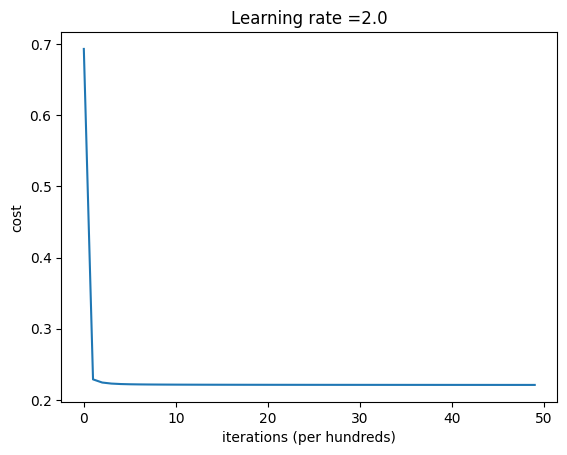

In [34]:
# Plot learning curve (with costs)
costs = np.squeeze(logistic_regression_model['costs'])
plt.plot(costs)
plt.ylabel('cost')
plt.xlabel('iterations (per hundreds)')
plt.title("Learning rate =" + str(logistic_regression_model["learning_rate"]))
plt.show()

In [35]:
#Reverse normalization
Y_prediction_train_real_scale = scaler_y.inverse_transform(logistic_regression_model["Y_prediction_train"].T)
Y_prediction_test_real_scale = scaler_y.inverse_transform(logistic_regression_model["Y_prediction_test"].T)

# tic-toc: time needed to predict the whole test set
tic = perf_counter()
predict(logistic_regression_model["w"], logistic_regression_model["b"], test_set_x_normalized)
toc = perf_counter()
predict_time = toc - tic

train_scores = evaluate(train_set_y_orig, Y_prediction_train_real_scale)
test_scores = evaluate(test_set_y_orig, Y_prediction_test_real_scale)

# CV and test side by side (same metrics, all in kW)
comparison = pd.DataFrame({"CV train (mean)": [best["train_" + m] for m in metrics],
                           "CV validation (mean)": [best["val_" + m] for m in metrics],
                           "CV validation (std)": [best["val_std_" + m] for m in metrics],
                           "final model train": [train_scores[m] for m in metrics],
                           "test": [test_scores[m] for m in metrics]},
                          index=metrics)

# one row for the results file
test_results = {"model": model_name, "learning_rate": learning_rate, "num_iterations": num_iterations}
test_results.update({"cv_val_" + m: best["val_" + m] for m in metrics})
test_results.update({"train_" + m: train_scores[m] for m in metrics})
test_results.update({"test_" + m: test_scores[m] for m in metrics})
test_results.update({"train_time_s": logistic_regression_model["train_time"],
                     "predict_time_test_s": predict_time,
                     "grid_search_time_s": toc_cv - tic_cv})
test_results = pd.DataFrame([test_results])

print("training time: %.2f s | prediction time (test set): %.4f s" % (logistic_regression_model["train_time"], predict_time))
comparison

training time: 8.46 s | prediction time (test set): 0.0037 s


,CV train (mean),CV validation (mean),CV validation (std),final model train,test
MAE,34.442127,33.950985,5.623441,34.619701,34.662520
MSE,3422.307454,3350.937546,1105.340804,3436.779776,3362.908933
RMSE,58.486707,57.112561,9.438903,58.624055,57.990593
R2,0.912711,0.866908,0.084886,0.910738,0.911879


<a name='7'></a>
##  7 - Results Analysis

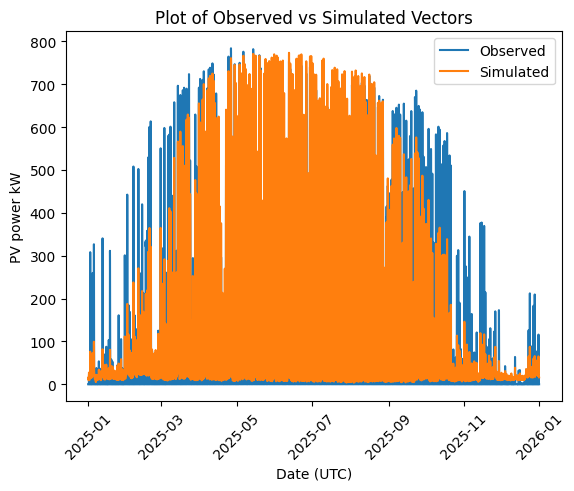

In [36]:
x = time[split:]                               
y1 = test_set_y_orig
y2 = Y_prediction_test_real_scale

plt.plot(x, y1, label='Observed')
plt.plot(x, y2, label='Simulated')
plt.title('Plot of Observed vs Simulated Vectors')
plt.xlabel('Date (UTC)')
plt.ylabel('PV power kW')
plt.ylim()
plt.legend()
plt.xticks(rotation=45)
plt.show()

## Feature Importance

Three ways to see which inputs matter for the PV output:

1. **Correlation** (Pearson, on the training set): linear relation between each input and the output, independent of the model. Fast, but it ignores interactions and non-linear effects.
2. **Model weights** (by hand from the equations): since $\hat{y} = \sigma(w^T x + b)$ and all inputs are min-max scaled to [0, 1], each $w_j$ directly shows how strongly and in which direction feature $j$ pushes the prediction. The sign gives the direction, $|w_j|$ the strength. This only works for the logistic regression (one weight per input), not for the neural networks.
3. **Permutation importance** (on the test set): one feature is randomly shuffled, which destroys its information, and the increase of the test RMSE is measured. The larger the increase, the more the model relies on that feature.

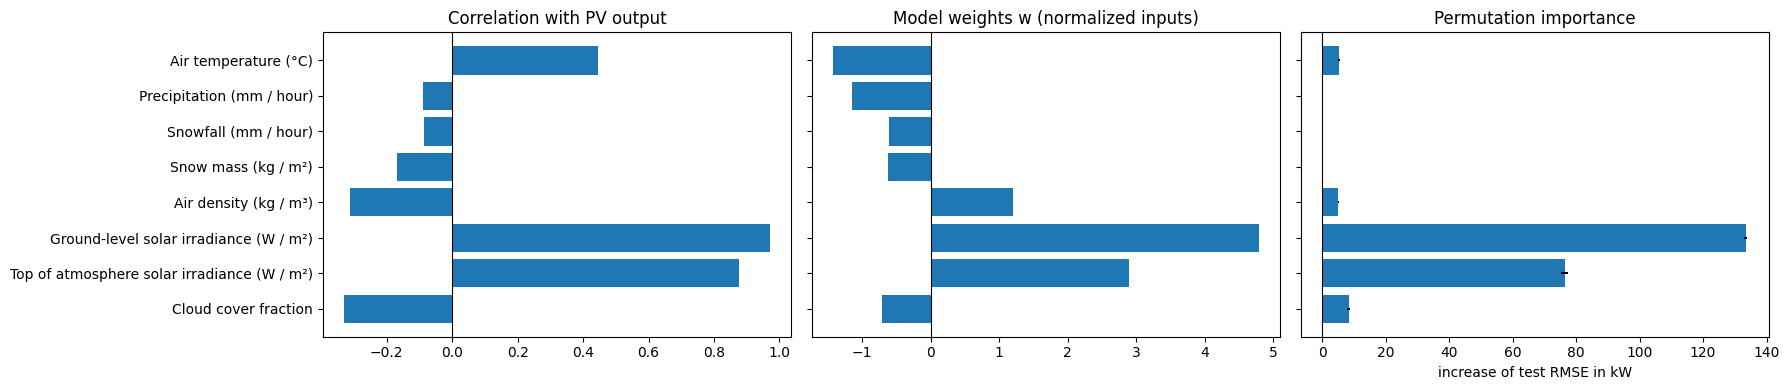

,model,feature,correlation_with_output,weight,abs_weight,permutation_RMSE_increase_kW,permutation_RMSE_increase_std
5,Logistic regression,Ground-level solar irradiance (W / m²),0.970442,4.785914,4.785914,133.426297,0.566167
6,Logistic regression,Top of atmosphere solar irradiance (W / m²),0.876627,2.900734,2.900734,76.323743,0.987528
7,Logistic regression,Cloud cover fraction,-0.330192,-0.703424,0.703424,8.325258,0.442575
0,Logistic regression,Air temperature (°C),0.445269,-1.423910,1.423910,5.237590,0.392949
4,Logistic regression,Air density (kg / m³),-0.312663,1.199951,1.199951,5.057719,0.093854
1,Logistic regression,Precipitation (mm / hour),-0.089098,-1.146754,1.146754,0.256107,0.015244
2,Logistic regression,Snowfall (mm / hour),-0.084976,-0.603277,0.603277,0.013877,0.007923
3,Logistic regression,Snow mass (kg / m²),-0.167289,-0.621304,0.621304,-0.107162,0.048531


In [48]:
feature_names = data.columns[0:8]
w = logistic_regression_model["w"]
b = logistic_regression_model["b"]

# readable feature names (used in the plot and in the results table)
label_map = {"t2m": "Air temperature (°C)",
             "prectotland": "Precipitation (mm / hour)",
             "precsnoland": "Snowfall (mm / hour)",
             "snomas": "Snow mass (kg / m²)",
             "rhoa": "Air density (kg / m³)",
             "swgdn": "Ground-level solar irradiance (W / m²)",
             "swtdn": "Top of atmosphere solar irradiance (W / m²)",
             "cldtot": "Cloud cover fraction"}
plot_labels = [label_map[f] for f in feature_names]

# 1. correlation of every input with the output (training set only)
correlation = data.iloc[:split].corr()[data.columns[-1]][feature_names]

# 2. weights of the model (inputs are normalized, so the weights are comparable)
weights = w.flatten()

# 3. permutation importance: shuffle one feature of the test set and measure the increase of the RMSE in kW
n_repeats = 5
rng = np.random.default_rng(0)
base_rmse = test_scores["RMSE"]
perm_importance = np.zeros((len(feature_names), n_repeats))

for j in range(len(feature_names)):
    for r in range(n_repeats):
        x_shuffled = test_set_x_normalized.copy()
        x_shuffled[j, :] = rng.permutation(x_shuffled[j, :])
        y_shuffled_kw = scaler_y.inverse_transform(predict(w, b, x_shuffled).T)
        perm_importance[j, r] = evaluate(test_set_y_orig, y_shuffled_kw)["RMSE"] - base_rmse

feature_importance = pd.DataFrame({"model": model_name,
                                   "feature": plot_labels,
                                   "correlation_with_output": correlation.values,
                                   "weight": weights,
                                   "abs_weight": np.abs(weights),
                                   "permutation_RMSE_increase_kW": perm_importance.mean(axis=1),
                                   "permutation_RMSE_increase_std": perm_importance.std(axis=1)})

fig, ax = plt.subplots(1, 3, figsize=(18, 4), sharey=True)

ax[0].barh(plot_labels, correlation.values)
ax[0].set_title('Correlation with PV output')
ax[1].barh(plot_labels, weights)
ax[1].set_title('Model weights w (normalized inputs)')
ax[2].barh(plot_labels, perm_importance.mean(axis=1), xerr=perm_importance.std(axis=1))
ax[2].set_title('Permutation importance')
ax[2].set_xlabel('increase of test RMSE in kW')

ax[0].invert_yaxis()    # order of the features

for a in ax:
    a.axvline(0, color='black', linewidth=0.8)

plt.tight_layout()
plt.show()

feature_importance.sort_values("permutation_RMSE_increase_kW", ascending=False)

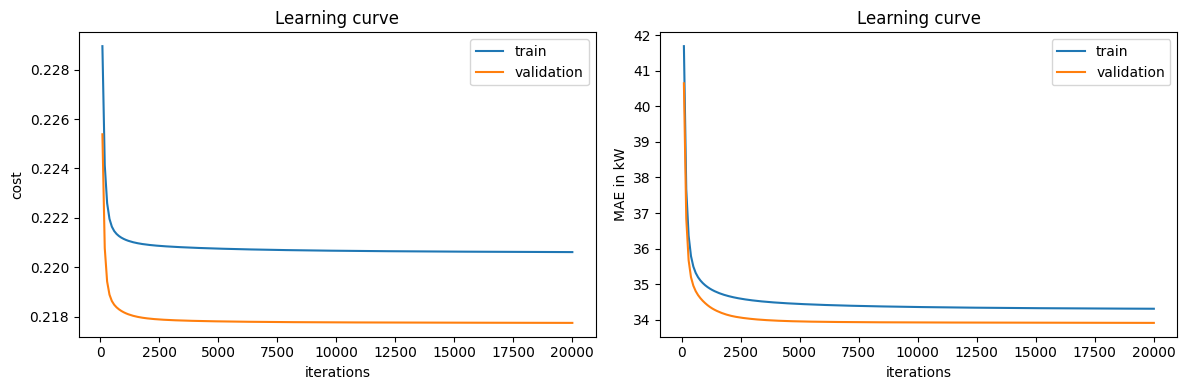

In [49]:
#  learning curves: train vs validation (mean over the CV folds)
total_iterations = 20000   
step = 100                 # evaluate every 100 iterations
n_points = total_iterations // step

train_cost = np.zeros((n_splits, n_points))
val_cost = np.zeros((n_splits, n_points))
train_mae = np.zeros((n_splits, n_points))
val_mae = np.zeros((n_splits, n_points))

for fold, (train_idx, val_idx) in enumerate(tscv.split(train_set_x_orig)):
    x_train = train_set_x_orig[train_idx]
    x_val = train_set_x_orig[val_idx]
    y_train = train_set_y_orig[train_idx]
    y_val = train_set_y_orig[val_idx]

    # same normalization as in the cross-validation
    scaler_x = MinMaxScaler(feature_range=(0,1))
    scaler_y = MinMaxScaler(feature_range=(0,1))
    x_train_normalized = scaler_x.fit_transform(x_train).T
    x_val_normalized = scaler_x.transform(x_val).T
    y_train_normalized = scaler_y.fit_transform(y_train).T
    y_val_normalized = scaler_y.transform(y_val).T

    y_range = np.max(y_train) - np.min(y_train)    #  convert the normalized error back to kW

    w, b = initialize_with_zeros(x_train_normalized.shape[0])

    for k in range(n_points):
        # continue the training for another 100 iterations
        params, grads, costs = optimize(w, b, x_train_normalized, y_train_normalized, step, learning_rate)
        w = params["w"]
        b = params["b"]

        train_cost[fold, k] = propagate(w, b, x_train_normalized, y_train_normalized)[1]
        val_cost[fold, k] = propagate(w, b, x_val_normalized, y_val_normalized)[1]

        train_mae[fold, k] = np.mean(np.abs(predict(w, b, x_train_normalized) - y_train_normalized)) * y_range
        val_mae[fold, k] = np.mean(np.abs(predict(w, b, x_val_normalized) - y_val_normalized)) * y_range

iterations = np.arange(step, total_iterations + 1, step)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

for i, (train_curve, val_curve, label) in enumerate([(train_cost, val_cost, 'cost'), (train_mae, val_mae, 'MAE in kW')]):
    ax[i].plot(iterations, train_curve.mean(axis=0), label='train')
    ax[i].plot(iterations, val_curve.mean(axis=0), label='validation')
    ax[i].set_xlabel('iterations')
    ax[i].set_ylabel(label)
    ax[i].set_title('Learning curve')
    ax[i].legend()

plt.tight_layout()
plt.show()

## Save the Results

Writes the CV table, the test results and the feature importance to `results/model_comparison.xlsx` (see "Documentation of the results" above).

In [39]:
save_results({"cv": cv_results,
              "test": test_results,
              "feature_importance": feature_importance}, model_name)

print("results saved to", results_file)

results saved to results/model_comparison.xlsx
